# neuro_dev_SOM

PhysiCell's `published/grammar_samples/user_projects/neuro_dev/config/PhysiCell_settings_SOM.xml` as a **self-contained notebook**. The model below is Python,
generated from that project's XML and rules CSV; nothing here reads a PhysiCell
file, builds an executable or parses an output folder.

| | |
|---|---|
| domain | 20 x 65 x 1 voxels, dx=20 um, 2D |
| substrates | reelin, rgc_taxis_factor |
| cell types | apical, pial, rgc, layer_6, layer_5, layer_4, layer_3, layer_2 |
| rules | 13 (13 runnable here) |
| initial cells | 268, from `data/neuro_dev_SOM_cells.csv` |

**Sections 3 to 7 are the point of the library**: each one is something the
XML-and-executable workflow cannot do at all, or can only do by editing C++,
recompiling and re-running from t=0.


In [1]:
import pathlib
import numpy as np, matplotlib.pyplot as plt
import pyphysicell as pc
from pyphysicell import viz

# the data this notebook needs sits next to it
DATA = next(p for p in (pathlib.Path('data'), pathlib.Path('notebooks/data'))
            if p.exists())
print('kernels:', pc.BACKEND, '|', pc.MAX_THREADS, 'threads', '| data:', DATA)

kernels: std::thread | 2 threads | data: data


## 1. The model is an object

Not a document to be parsed at start-up: a value you can read, edit, copy, hash
and generate. Everything below came from the project's XML.

In [2]:
# Generated by pyphysicell.codegen from published/grammar_samples/user_projects/neuro_dev/config/PhysiCell_settings_SOM.xml.
# Values are PhysiCell's: minutes, microns, and each substrate's own units.


model = pc.Model(name="neuro_dev")
model.domain = pc.Domain(x_min=-205.0, x_max=205.0, y_min=-200.0, y_max=1100.0, z_min=-10.0, z_max=10.0, dx=20.0, dy=20.0, dz=20.0, use_2D=True)
model.time = pc.Time(dt_diffusion=0.01, dt_mechanics=0.1, dt_phenotype=6.0, max_time=14400.0, time_units="min", space_units="micron")
model.random_seed = 0
model.virtual_wall = True
model.omp_num_threads = 4
model.calculate_gradients = True
model.track_internalized_substrates = True
model.disable_automated_spring_adhesions = False
model.legacy_division_orientation = False
model.save = pc.SaveOptions(folder="outputs/neuro_dev/SOM", full_interval=60.0, full_enabled=True, svg_interval=60.0, svg_enabled=True)

# --- substrates --------------------------------------------------------------
model.substrates = [
    pc.Substrate(
        "reelin",
        diffusion_coefficient=100.0,
        decay_rate=0.1,
        initial_condition=0.0,
        dirichlet_enabled=False, dirichlet_value=0.0,
        dirichlet_faces={"xmax": (False, 0.0), "xmin": (False, 0.0), "ymax": (False, 0.0), "ymin": (False, 0.0), "zmax": (False, 0.0), "zmin": (False, 0.0)},
    ),
    pc.Substrate(
        "rgc_taxis_factor",
        diffusion_coefficient=10000.0,
        decay_rate=1.0,
        initial_condition=0.0,
        dirichlet_enabled=False, dirichlet_value=0.0,
        dirichlet_faces={"xmax": (False, 0.0), "xmin": (False, 0.0), "ymax": (False, 0.0), "ymin": (False, 0.0), "zmax": (False, 0.0), "zmin": (False, 0.0)},
    ),
]

# --- cell types --------------------------------------------------------------
ct0 = pc.CellType("apical", ID=0)
ct0.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct0.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct0.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct0.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"apical": 1.0, "pial": 1.0, "rgc": 1.0, "layer_6": 1.0, "layer_5": 1.0, "layer_4": 1.0, "layer_3": 1.0, "layer_2": 1.0})
ct0.motility = pc.Motility(speed=1.0, persistence_time=5.0, migration_bias=0.5, enabled=False, use_2D=True, chemotaxis_enabled=False, chemotaxis_substrate="rgc_taxis_factor", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"reelin": 0.0, "rgc_taxis_factor": 0.0})
ct0.secretion = {
    "reelin": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0),
    "rgc_taxis_factor": pc.SecretionEntry(secretion_rate=1.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct0.custom_data = {"sample": 1.0}
ct0.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=100.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    attack_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    fusion_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    transformation_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    immunogenicities={})
ct0.custom_conserved = {"sample": False}

ct1 = pc.CellType("pial", ID=1)
ct1.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct1.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct1.volume = pc.Volume(total=499.0, fluid_fraction=0.75, nuclear=108.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct1.mechanics = pc.Mechanics(cell_cell_adhesion_strength=1.0, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.1, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"apical": 0.0, "pial": 1.0, "rgc": 1.0, "layer_6": 1.0, "layer_5": 1.0, "layer_4": 1.0, "layer_3": 1.0, "layer_2": 1.0})
ct1.motility = pc.Motility(speed=0.0, persistence_time=5.0, migration_bias=1.0, enabled=True, use_2D=True, chemotaxis_enabled=True, chemotaxis_substrate="rgc_taxis_factor", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"reelin": 0.0, "rgc_taxis_factor": -1.0})
ct1.secretion = {
    "reelin": pc.SecretionEntry(secretion_rate=10.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0),
    "rgc_taxis_factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct1.custom_data = {"sample": 1.0}
ct1.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    attack_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    fusion_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    transformation_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    immunogenicities={})
ct1.custom_conserved = {"sample": False}

ct2 = pc.CellType("rgc", ID=2)
ct2.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0013},
         fixed_duration={(0, 0): True},
         asymmetric_division={"apical": 0.0, "pial": 0.0, "rgc": 1.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0})
ct2.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct2.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct2.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.4, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"apical": 1.0, "pial": 1.0, "rgc": 0.0, "layer_6": 1.0, "layer_5": 1.0, "layer_4": 1.0, "layer_3": 1.0, "layer_2": 1.0})
ct2.motility = pc.Motility(speed=1.0, persistence_time=1.0, migration_bias=0.5, enabled=True, use_2D=True, chemotaxis_enabled=True, chemotaxis_substrate="rgc_taxis_factor", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"reelin": 0.0, "rgc_taxis_factor": 0.0})
ct2.secretion = {
    "reelin": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0),
    "rgc_taxis_factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct2.custom_data = {"sample": 1.0}
ct2.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    attack_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    fusion_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    transformation_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    immunogenicities={})
ct2.custom_conserved = {"sample": False}

ct3 = pc.CellType("layer_6", ID=3)
ct3.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct3.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct3.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct3.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.0, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"apical": 1.0, "pial": 0.0, "rgc": 1.0, "layer_6": 0.0, "layer_5": 1.0, "layer_4": 1.0, "layer_3": 1.0, "layer_2": 1.0})
ct3.motility = pc.Motility(speed=2.0, persistence_time=1.0, migration_bias=0.5, enabled=True, use_2D=True, chemotaxis_enabled=True, chemotaxis_substrate="reelin", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"reelin": 0.0, "rgc_taxis_factor": 0.0})
ct3.secretion = {
    "reelin": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0),
    "rgc_taxis_factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct3.custom_data = {"sample": 1.0}
ct3.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    attack_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    fusion_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    transformation_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    immunogenicities={})
ct3.custom_conserved = {"sample": False}

ct4 = pc.CellType("layer_5", ID=4)
ct4.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct4.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct4.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct4.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.0, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"apical": 1.0, "pial": 0.0, "rgc": 1.0, "layer_6": 1.0, "layer_5": 0.0, "layer_4": 1.0, "layer_3": 1.0, "layer_2": 1.0})
ct4.motility = pc.Motility(speed=2.0, persistence_time=1.0, migration_bias=0.5, enabled=True, use_2D=True, chemotaxis_enabled=True, chemotaxis_substrate="reelin", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"reelin": 0.0, "rgc_taxis_factor": 0.0})
ct4.secretion = {
    "reelin": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0),
    "rgc_taxis_factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct4.custom_data = {"sample": 1.0}
ct4.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    attack_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    fusion_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    transformation_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    immunogenicities={})
ct4.custom_conserved = {"sample": False}

ct5 = pc.CellType("layer_4", ID=5)
ct5.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct5.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct5.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct5.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.0, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"apical": 1.0, "pial": 0.0, "rgc": 1.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0})
ct5.motility = pc.Motility(speed=2.0, persistence_time=1.0, migration_bias=0.5, enabled=True, use_2D=True, chemotaxis_enabled=True, chemotaxis_substrate="reelin", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"reelin": 0.0, "rgc_taxis_factor": 0.0})
ct5.secretion = {
    "reelin": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0),
    "rgc_taxis_factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct5.custom_data = {"sample": 1.0}
ct5.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    attack_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    fusion_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    transformation_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    immunogenicities={})
ct5.custom_conserved = {"sample": False}

ct6 = pc.CellType("layer_3", ID=6)
ct6.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct6.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct6.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct6.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.0, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"apical": 1.0, "pial": 0.0, "rgc": 1.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0})
ct6.motility = pc.Motility(speed=2.0, persistence_time=1.0, migration_bias=0.5, enabled=True, use_2D=True, chemotaxis_enabled=True, chemotaxis_substrate="reelin", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"reelin": 0.0, "rgc_taxis_factor": 0.0})
ct6.secretion = {
    "reelin": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0),
    "rgc_taxis_factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct6.custom_data = {"sample": 1.0}
ct6.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    attack_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    fusion_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    transformation_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    immunogenicities={})
ct6.custom_conserved = {"sample": False}

ct7 = pc.CellType("layer_2", ID=7)
ct7.cycle = pc.Cycle(code=5, name="live",
         transition_rates={(0, 0): 0.0},
         fixed_duration={(0, 0): False})
ct7.deaths = {
    "apoptosis": pc.DeathModel(code=100, name="apoptosis", death_rate=0.0,
              phase_durations={0: 516.0},
              unlysed_fluid_change_rate=0.05,
              lysed_fluid_change_rate=0.0,
              cytoplasmic_biomass_change_rate=0.0166667,
              nuclear_biomass_change_rate=0.00583333,
              calcification_rate=0.0,
              relative_rupture_volume=2.0),
    "necrosis": pc.DeathModel(code=101, name="necrosis", death_rate=0.0,
              phase_durations={0: 0.0, 1: 86400.0},
              unlysed_fluid_change_rate=0.0111667,
              lysed_fluid_change_rate=0.000833333,
              cytoplasmic_biomass_change_rate=5.33333e-05,
              nuclear_biomass_change_rate=0.00216667,
              calcification_rate=0.0,
              relative_rupture_volume=2.0)}
ct7.volume = pc.Volume(total=2494.0, fluid_fraction=0.75, nuclear=540.0, fluid_change_rate=0.05, cytoplasmic_biomass_change_rate=0.0045, nuclear_biomass_change_rate=0.0055, calcified_fraction=0.0, calcification_rate=0.0, relative_rupture_volume=2.0)
ct7.mechanics = pc.Mechanics(cell_cell_adhesion_strength=0.0, cell_cell_repulsion_strength=10.0, relative_maximum_adhesion_distance=1.25, attachment_elastic_constant=0.01, attachment_rate=0.0, detachment_rate=0.0, maximum_number_of_attachments=12, cell_BM_adhesion_strength=4.0, cell_BM_repulsion_strength=100.0, adhesion_affinities={"apical": 1.0, "pial": 0.0, "rgc": 1.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0})
ct7.motility = pc.Motility(speed=2.0, persistence_time=1.0, migration_bias=0.5, enabled=True, use_2D=True, chemotaxis_enabled=True, chemotaxis_substrate="reelin", chemotaxis_direction=1.0, advanced_chemotaxis=False, normalize_each_gradient=False, sensitivities={"reelin": 0.0, "rgc_taxis_factor": 0.0})
ct7.secretion = {
    "reelin": pc.SecretionEntry(secretion_rate=0.0, secretion_target=0.0, uptake_rate=0.0, net_export_rate=0.0),
    "rgc_taxis_factor": pc.SecretionEntry(secretion_rate=0.0, secretion_target=1.0, uptake_rate=0.0, net_export_rate=0.0)}
ct7.custom_data = {"sample": 1.0}
ct7.interactions = pc.Interactions(
    apoptotic_phagocytosis_rate=0.0,
    necrotic_phagocytosis_rate=0.0,
    other_dead_phagocytosis_rate=0.0,
    attack_damage_rate=1.0,
    attack_duration=0.1,
    damage_rate=0.0,
    damage_repair_rate=0.0,
    live_phagocytosis_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    attack_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    fusion_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    transformation_rates={"apical": 0.0, "pial": 0.0, "rgc": 0.0, "layer_6": 0.0, "layer_5": 0.0, "layer_4": 0.0, "layer_3": 0.0, "layer_2": 0.0},
    immunogenicities={})
ct7.custom_conserved = {"sample": False}

model.cell_types = [ct0, ct1, ct2, ct3, ct4, ct5, ct6, ct7]

model.user_parameters = {"number_of_cells": 0}

# --- rules (cell behavior hypothesis grammar) ---------------------------------
model.rules = [
    pc.Rule("rgc", "contact with apical", "decreases", "migration speed", max_response=0.0, half_max=0.5, hill_power=8.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "decreases", "cycle entry", max_response=0.00085, half_max=9206.0, hill_power=10.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "increases", "asymmetric division to layer_6", max_response=1.0, half_max=1440.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "decreases", "asymmetric division to layer_6", max_response=0.0, half_max=5007.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "increases", "asymmetric division to layer_5", max_response=1.0, half_max=5007.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "decreases", "asymmetric division to layer_5", max_response=0.0, half_max=6554.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "increases", "asymmetric division to layer_4", max_response=1.0, half_max=6554.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "decreases", "asymmetric division to layer_4", max_response=0.0, half_max=9010.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "increases", "asymmetric division to layer_3", max_response=1.0, half_max=9010.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "decreases", "asymmetric division to layer_3", max_response=0.0, half_max=10985.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "increases", "asymmetric division to layer_2", max_response=1.0, half_max=10985.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "decreases", "asymmetric division to layer_2", max_response=0.0, half_max=12960.0, hill_power=256.0, apply_to_dead=False),
    pc.Rule("rgc", "time", "increases", "apoptosis", max_response=1.0, half_max=12960.0, hill_power=256.0, apply_to_dead=False),
]

# --- initial conditions ------------------------------------------------------
# Initial conditions live beside this notebook (74 apical, 25 rgc, 169 pial).
CELLS = DATA / 'neuro_dev_SOM_cells.csv'
model.initial_cells = pc.read_cells_csv(CELLS, model.cell_type_names)
print(f'{len(model.initial_cells)} cells from {CELLS.name}')

268 cells from neuro_dev_SOM_cells.csv


In [3]:
print(model.summary())
print('content hash:', model.hash, '-- changes with any edit, so runs are traceable')

model 'neuro_dev'  [bb376d7910a0]
  domain     20 x 65 x 1 voxels, dx=20 um, 2D
  time       dt_diff=0.01 dt_mech=0.1 dt_pheno=6  max_time=14400 min
  substrates reelin, rgc_taxis_factor
  cell types apical, pial, rgc, layer_6, layer_5, layer_4, layer_3, layer_2
  rules      13
  initial    268 cells
content hash: bb376d7910a0 -- changes with any edit, so runs are traceable


## 2. Answers before you simulate

These cost milliseconds and need no run at all. `check()` is dimensional analysis
of the model as written; the cycle duration is closed-form from the phase graph;
a rule's response curve is a pure function of its signal.

In [4]:
print(pc.check(model))

check: 'neuro_dev' [bb376d7910a0]
  [WARN    ] reelin                     L=sqrt(D/lambda)=    31.6 um =   1.6 dx
  [marginal] rgc_taxis_factor           L=sqrt(D/lambda)=   100.0 um =   5.0 dx
  [info    ] apical                     does not cycle on its own (rate 0; a rule may drive it)
  [info    ] pial                       does not cycle on its own (rate 0; a rule may drive it)
  [info    ] rgc                        cycle mean duration 12.8 h (from the phase graph, no simulation)
  [info    ] layer_6                    does not cycle on its own (rate 0; a rule may drive it)
  [info    ] layer_5                    does not cycle on its own (rate 0; a rule may drive it)
  [info    ] layer_4                    does not cycle on its own (rate 0; a rule may drive it)
  [info    ] layer_3                    does not cycle on its own (rate 0; a rule may drive it)
  [info    ] layer_2                    does not cycle on its own (rate 0; a rule may drive it)
  [info    ] mesh 20x65x1 = 1

In [5]:
for ct in model.cell_types:
    d = ct.cycle.mean_duration()
    print(f'{ct.name:<28} cycle {d/60:8.1f} h' if np.isfinite(d)
          else f'{ct.name:<28} does not cycle on its own')

apical                       does not cycle on its own
pial                         does not cycle on its own
rgc                          cycle     12.8 h
layer_6                      does not cycle on its own
layer_5                      does not cycle on its own
layer_4                      does not cycle on its own
layer_3                      does not cycle on its own
layer_2                      does not cycle on its own


In rgc cells, contact with apical decreases migration speed towards 0 with half-max 0.5 and Hill power 8.
In rgc cells, time decreases cycle entry towards 0.00085 with half-max 9206 and Hill power 10.
In rgc cells, time increases asymmetric division to layer_6 towards 1 with half-max 1440 and Hill power 256.


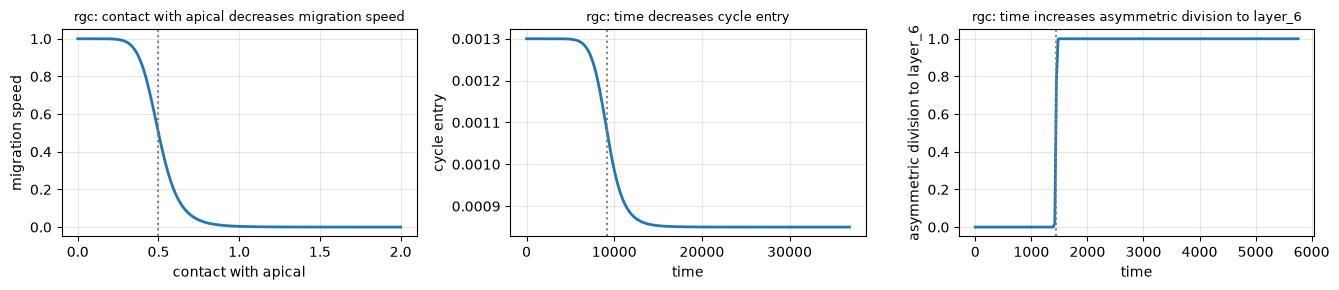

In [6]:
d = pc.Dictionary(model)
shown = [r for r in model.rules if d.supports_signal(r.signal)
         and d.supports_behavior(r.behavior)][:3]
fig, axes = plt.subplots(1, len(shown), figsize=(4.5 * len(shown), 3))
for ax, r in zip(np.atleast_1d(axes), shown):
    viz.plot_rule(r, d.base_behavior(r.cell_type, r.behavior), ax=ax)
    print(r.english())
plt.tight_layout()

## 3. Run it, and keep the simulation

`sim` stays alive afterwards: its cells and fields are NumPy arrays you can read
and change, and the run can be continued. The executable exits and leaves files.

This demo covers 923.08 min of the 14400 min the project's own config asks for -- roughly 1.2 turns of its fastest cycle.

In [7]:
sim = pc.Simulation(model, seed=model.random_seed)
if not sim.cells.n:
    print(pc.initial.apply(sim))
scalars = sim.run(until=923.08, record_every=76.9233)
print(sim, f'| {sim.wall_time:.1f} s')
sim.dataframe().head(3)

<Simulation 'neuro_dev' t=923.1 min cells=293 backend=std::thread:2> | 23.8 s


,ID,x,y,z,type,volume,radius,phase,dead,pressure,cell_type
0,0,-204.999999,-199.999999,0.0,0,2494.0,8.412711,0,False,1.409121,apical
1,1,-180.749508,-199.999999,0.0,0,2494.0,8.412711,0,False,1.223426,apical
2,2,-165.588621,-199.999999,0.0,0,2494.0,8.412711,0,False,2.057162,apical


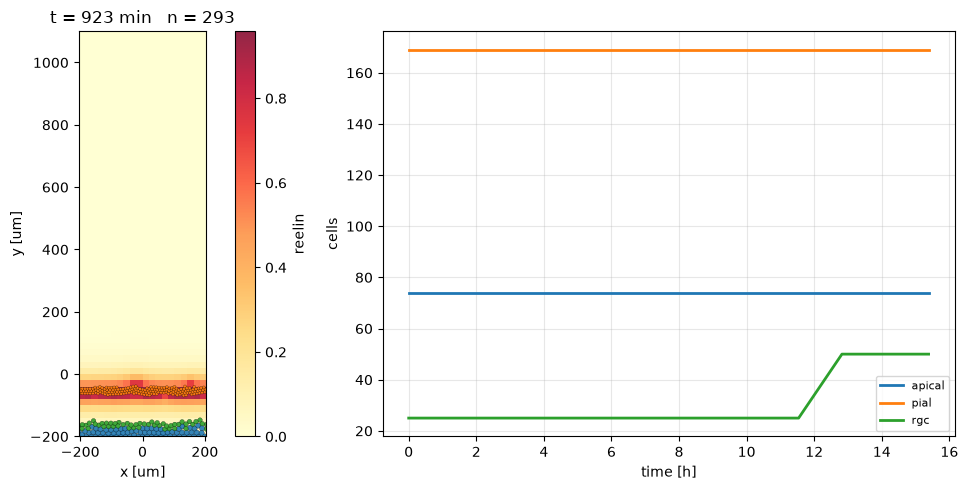

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
viz.plot_cells(sim, substrate='reelin', ax=axes[0])
viz.plot_populations(scalars, ax=axes[1])
plt.tight_layout()

## 4. Steer it while it runs

Change the state mid-run and carry on from where you are. In the file workflow
this is a new XML and a new run from t=0, or custom C++ and a recompile.

mean reelin 0.0614 -> 0.0609


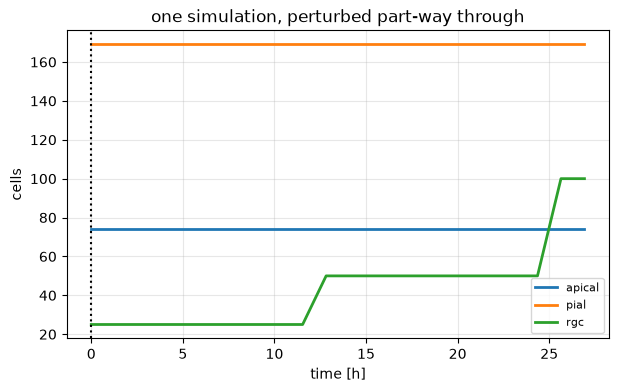

In [9]:
before = sim.microenvironment['reelin'].mean()
sim.microenvironment.density[..., 0] = 0.0      # remove reelin everywhere
sim.run(until=sim.t + 692.31, record_every=76.9233)
after = sim.microenvironment['reelin'].mean()
print(f'mean reelin {before:.3g} -> {after:.3g}')
viz.plot_populations(sim.scalars)
plt.axvline(sim.scalars.times[0] / 60, ls=':', c='k')
plt.title('one simulation, perturbed part-way through');

## 5. Two futures from one state

`branch()` is a deepcopy of the whole simulation, because all of the state is
Python. PhysiCell keeps its state in process globals, so a second simulation in
the same process is impossible there and a counterfactual means re-running from
the beginning with a different input file.

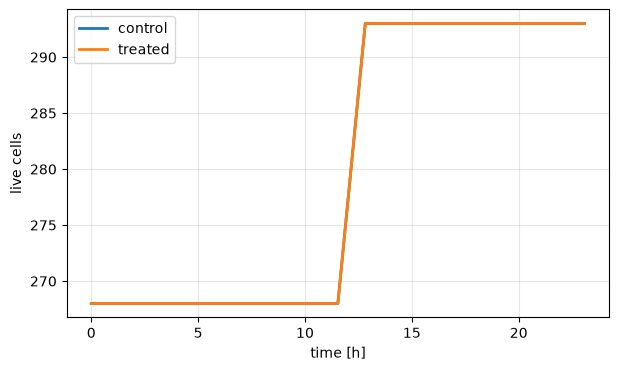

In [10]:
base = pc.Simulation(model, seed=model.random_seed)
if not base.cells.n:
    pc.initial.apply(base)
base.run(until=692.31, record_every=76.9233)

control = base.branch()
treated = base.branch()
treated.microenvironment.density[..., 0] *= 0.1   # 90% knock-down
control.run(until=control.t + 692.31, record_every=76.9233)
treated.run(until=treated.t + 692.31, record_every=76.9233)

fig, ax = plt.subplots(figsize=(7, 4))
for name, s in (('control', control.scalars), ('treated', treated.scalars)):
    total = np.sum([v for v in s.counts.values()], axis=0)
    ax.plot(np.asarray(s.times) / 60, total, lw=2, label=name)
ax.set_xlabel('time [h]'); ax.set_ylabel('live cells'); ax.legend(); ax.grid(alpha=0.3);

## 6. Logic the rules grammar cannot express

A CBHG rule is a Hill function of one cell's own signals: it cannot see where a
cell is, or how it ranks against the rest of the population. A hook is arbitrary
Python over the whole population, called once per phenotype step on arrays, so
both become possible -- and still no C++.

In [11]:
probe = pc.Simulation(model, seed=model.random_seed)
if not probe.cells.n:
    pc.initial.apply(probe)
log = []

@probe.hook('phenotype', cell_type='pial')
def spatial_and_population_relative(ctx):
    p = ctx.signals['pressure']
    crowded = p >= np.quantile(p, 0.9) if ctx.n > 1 else np.zeros(ctx.n, bool)
    left = ctx.position[:, 0] < 0
    # population-relative: the most crowded tenth stops cycling
    ctx.behaviors['cycle entry'] = np.where(crowded, 0.0,
                                            ctx.behaviors['cycle entry'])
    # spatial: cells in the left half of the domain stop migrating
    ctx.behaviors['migration speed'] = np.where(left, 0.0,
                                                ctx.behaviors['migration speed'])
    log.append((ctx.t, int(crowded.sum()), float(left.mean())))

probe.run(until=692.31, record_every=76.9233)
c = probe.cells
mine = c.view('type_idx') == probe.type_index['pial']
left = mine & (c.view('position')[:, 0] < 0)
right = mine & (c.view('position')[:, 0] >= 0)
print(f'hook fired {len(log)} times, one call per phenotype step for all {mine.sum()} cells')
print(f"  mean migration speed   left {c.view('motility_speed')[left].mean():.3f}   right {c.view('motility_speed')[right].mean():.3f}")
print(f"  mean cycle entry rate  crowded decile is held at 0; population mean {c.view('cycle_entry_rate')[mine].mean():.3e}")

hook fired 116 times, one call per phenotype step for all 169 cells
  mean migration speed   left 0.000   right 0.000
  mean cycle entry rate  crowded decile is held at 0; population mean 0.000e+00


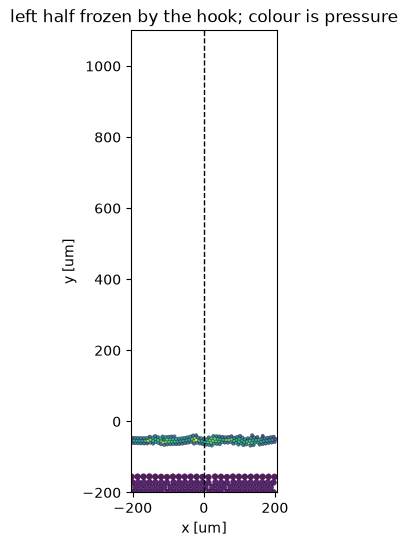

In [12]:
fig, ax = plt.subplots(figsize=(6, 6))
viz.plot_cells(probe, color_by='pressure', ax=ax)
ax.axvline(0, ls='--', c='k', lw=1)
ax.set_title('left half frozen by the hook; colour is pressure');

## 7. A sweep in one process

Varying the cycle transition rate of rgc, with replicates. No files, no subprocesses, no recompilation --
the models and the simulations are objects, so N of them are just N objects.

*That parameter was not chosen by hand.* The generator screened every knob this
model exposes -- rule half-maxes and saturated responses, cycle and death rates,
migration speed, substrate decay -- at half and double its published value, and
kept the one that moved an outcome most (200% spread at x4). Most knobs
in a
published model move nothing at its own parameters, which is itself worth
knowing before you spend a cluster on a sweep.

In [13]:
def change(m, value):
    m.cell_type('rgc').cycle.transition_rates[(0, 0)] = value

df, runs = pc.sweep(model, change, [0.000325, 0.0013, 0.0052], until=692.31,
                    replicates=2, progress=True)
df[['value', 'replicate', 'cells', 'births', 'deaths', 'spread_um',
    'mean_pressure', 'wall_s']]

      0.000325  rep 0  ->     268 cells (18.1 s)


      0.000325  rep 1  ->     268 cells (17.3 s)


        0.0013  rep 0  ->     268 cells (19.5 s)


        0.0013  rep 1  ->     268 cells (18.7 s)


        0.0052  rep 0  ->     443 cells (20.6 s)


        0.0052  rep 1  ->     443 cells (16.9 s)


,value,replicate,cells,births,deaths,spread_um,mean_pressure,wall_s
0,0.000325,0,268,0,0,132.21,2.5815,18.14
1,0.000325,1,268,0,0,132.54,2.5475,17.29
2,0.001300,0,268,0,0,132.42,2.6777,19.50
3,0.001300,1,268,0,0,132.68,2.7505,18.70
4,0.005200,0,443,175,0,133.22,10.4907,20.60
5,0.005200,1,443,175,0,133.17,10.4766,16.92


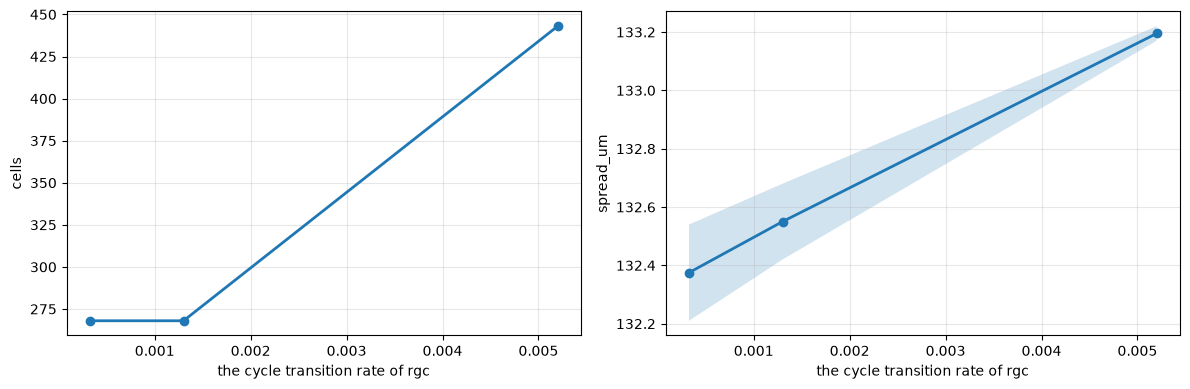

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pc.plot_sweep(df, 'cells', ax=axes[0], label='live cells')
pc.plot_sweep(df, 'spread_um', ax=axes[1], label='spread (RMS radius)')
axes[0].set_xlabel('the cycle transition rate of rgc'); axes[1].set_xlabel('the cycle transition rate of rgc')
plt.tight_layout()

## 8. Stop when something happens

A question like *when* does this model cross a level is a stopping condition
here, and a post-hoc search through saved snapshots otherwise.

The level is read off the run in section 3 rather than guessed, so the condition
is an event this model really reaches. An earlier version of this notebook picked
a threshold a priori and ran to its limit in 19 of 37 projects, demonstrating
nothing.

In [15]:
import numpy as np
h = sim.scalars
t = np.asarray(h.times, dtype=float)
# sections 4-6 steered this same sim, so calibrate on the untouched part
keep = t <= 923.08
t = t[keep]
series = {}
if h.counts:
    series['live cells'] = np.asarray([sum(v) for v in zip(*h.counts.values())],
                                      dtype=float)[keep]
series['dead cells'] = np.asarray(h.dead, dtype=float)[keep]
series['cumulative births'] = np.asarray(h.births, dtype=float)[keep]
series['cumulative deaths'] = np.asarray(h.deaths, dtype=float)[keep]
for _s, _v in h.mean_substrate.items():
    series[f'mean {_s}'] = np.asarray(_v, dtype=float)[keep]

def moved(v):
    scale = max(float(np.abs(v).max()), 1e-12)
    return max(abs(v[-1] - v[0]), v.max() - v.min()) / scale

name, y = max(series.items(), key=lambda kv: moved(kv[1]))
y0, lo, hi, end = float(y[0]), float(y.min()), float(y.max()), float(y[-1])
if end != y0:                      # 60% of the way to where it ended
    rising, level = end > y0, y0 + 0.6 * (end - y0)
else:                              # it came back: aim at the far extreme
    rising = (hi - y0) >= (y0 - lo)
    level = y0 + 0.6 * ((hi - y0) if rising else (lo - y0))
live = moved(y) > 0
print(f'{sum(moved(v) > 0 for v in series.values())} of {len(series)} recorded observables moved')
if live:
    crossed = t[np.argmax((y >= level) if rising else (y <= level))]
    print(f'watching {name}: the baseline crossed {level:.4g} at t = {crossed:.1f} min')
else:
    print('nothing this model records changes over the demo window')

4 of 6 recorded observables moved
watching cumulative births: the baseline crossed 15 at t = 769.2 min


In [16]:
readers = {'live cells': lambda s: float((s.cells.view('dead') == 0).sum()),
           'dead cells': lambda s: float((s.cells.view('dead') == 1).sum()),
           'cumulative births': lambda s: float(s._births),
           'cumulative deaths': lambda s: float(s._deaths)}
for _s in model.substrate_names:
    readers[f'mean {_s}'] = (lambda n: lambda s: float(s.microenvironment[n].mean()))(_s)
read = readers[name]

watch = pc.Simulation(model, seed=model.random_seed)
if not watch.cells.n:
    pc.initial.apply(watch)
limit = 3692.32
watch.run(until=limit, record_every=76.9233,
          stop_when=(lambda s: (read(s) >= level) if rising else (read(s) <= level))
                    if live else None)
print(f'stopped at t = {watch.t:.1f} min of a {limit:.0f} min limit, {name} = {read(watch):.4g}')
if live:
    assert watch.t < limit, 'the stopping condition never fired'

stopped at t = 762.0 min of a 3692 min limit, cumulative births = 25
